<div style="border-left:6px solid #00897B;padding:12px 18px;background:#F5F5F5">
<span style="color:#00897B;font-weight:bold">PAUL MINCHELLA · ONLINE LEARNING · SOLUTIONS</span>
<h1 style="color:#283593">Learning one day at a time</h1>
<b>OGD, OGD + Ridge, and newsvendor loss on a real demand stream</b><br>
Questions, worked code, and explanations · Suggested duration: 2h30
</div>

This practical accompanies [the course slides](../Cours_Online_Learning.pdf). We forecast the daily number
of bicycles rented in Washington (Capital Bikeshare) and learn **after**, never before, the release
of each observation. The dataset is small enough to implement each algorithm by hand,
without hiding the updates in a library.

**Weather scenario for this practical.** We assume that the temperature (`temp`), weather conditions (`weathersit`),
and wind speed (`windspeed`) on day $t$ are known **before** predicting that day's demand.
Demand $y_t$ remains unknown until after the prediction. If daily weather aggregates are actually unavailable
in advance, this assumption would represent an idealized scenario (a “weather oracle”): operational forecasts would be needed.

### Objectives

By the end of this practical, you will be able to:

1. describe a time series and identify the variables available **before** the decision;
2. check the assumptions underlying regret guarantees (compact domain, bounded covariates and target);
3. implement projected OGD for squared loss, with and without ridge;
4. implement OGD for newsvendor loss and observe that the optimum is the critical quantile $\tau = c_b/(c_b+c_h)$;
5. evaluate properly (training set then test set, predict before learning) using RMSE and average regret.

### Outline

| Part | Content | Slides |
|:--|:--|:--|
| **0** | Packages and data | — |
| **1** | Descriptive statistics | 9–14 |
| **2** | Online learning: assumptions, covariates, protocol, OGD, Ridge, Newsvendor | protocol 15–25; regret 26–29; OGD 44–49; regression 53–59; inventory 60–64 |
| **3** | Final metrics: RMSE, average regret, conclusion | 26–29, 65 |

<div style="border-left:4px solid #000000;padding:8px 14px;background:#E3F2FD;color:#black">

**Reminder — moving average**

A moving average with window size $w$ replaces each value with the average of $w$ neighboring values. It smooths daily
noise to reveal the trend and seasonality.

- **Trailing** (causal) moving average, which uses only the past:

$$
\bar y_t^{\,\text{trailing}} = \frac1w \sum_{k=0}^{w-1} y_{t-k}.
$$

- **Centered** moving average, which uses as many days after $t$ as before:

$$
\bar y_t^{\,\text{centered}} = \frac1w \sum_{k=-\lfloor w/2 \rfloor}^{\lceil w/2 \rceil - 1} y_{t+k}.
$$

The centered version is better aligned with the series: it is the right tool for *describing* it. It looks into the future,
so it must **never** be used for *forecasting*. In pandas: <code style="color:#000000;background:transparent">s.rolling(w).mean()</code> (trailing) and
<code style="color:#000000;background:transparent">s.rolling(w, center=True).mean()</code> (centered).

</div>

# Part 0 — Packages and data

We import only what is needed: NumPy for algebra, pandas for the data table, Matplotlib for
plots, and two SciPy functions (a root-finding routine and a linear solver) used
only to compute the **hindsight comparators** in Part 3. The online algorithms are implemented by hand.

In [1]:
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq, linprog
from IPython.display import display

DATA_DIR = Path.cwd() / "online_learning_bike_sharing_data"
DATA_URL = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"

PALETTE = {
    "teal": "#00897B",
    "skyblue": "#81D4FA",
    "blue": "#42A5F5",
    "darkblue": "#283593",
    "orange": "#FB8C00",
    "purple": "#8E24AA",
}
# One color and line style per model (the style also helps with B&W printing).
COLORS = {
    "Naive (previous day)": PALETTE["skyblue"],
    "Naive (previous week)": PALETTE["teal"],
    "OGD": PALETTE["blue"],
    "OGD + Ridge": PALETTE["darkblue"],
    "Newsvendor (no covariates)": PALETTE["orange"],
    "Newsvendor (contextual)": PALETTE["purple"],
}
STYLES = {
    "Naive (previous day)": ":", "Naive (previous week)": ":",
    "OGD": "-", "OGD + Ridge": "-.",
    "Newsvendor (no covariates)": "--", "Newsvendor (contextual)": "-",
}
plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.2,
    "axes.titleweight": "bold", "axes.labelcolor": "#333333", "lines.linewidth": 2.0,
    "axes.prop_cycle": plt.cycler(color=[PALETTE["teal"], PALETTE["blue"], PALETTE["orange"]]),
})
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 150)

In [2]:
def load_daily_data(data_dir=DATA_DIR, url=DATA_URL):
    """Loads day.csv: uses the local cache if available, otherwise downloads the UCI archive."""
    data_dir.mkdir(parents=True, exist_ok=True)
    csv_path = data_dir / "day.csv"
    if not csv_path.exists():
        print(f"Downloading from {url} ...")
        with urlopen(url, timeout=60) as response:
            archive = ZipFile(BytesIO(response.read()))
        csv_path.write_bytes(archive.read("day.csv"))  # read only the expected archive member
    return pd.read_csv(csv_path, parse_dates=["dteday"])


daily = load_daily_data()
print("Data loaded from:", DATA_DIR / "day.csv")

Data loaded from: /home/paulminchella/Dev/Master-MIASHS/M2_OnlineLearning/Travail_Newsvendor/online_learning_bike_sharing_data/day.csv


# Part 1 — Descriptive statistics

**Dataset:** [UCI Bike Sharing](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset),
DOI [10.24432/C5W894](https://doi.org/10.24432/C5W894), CC BY 4.0 license. We use `day.csv`:
one row per day, from 1 January 2011 to 31 December 2012. Requested citation: Hadi Fanaee-T and João Gama (2013),
*Event labeling combining ensemble detectors and background knowledge*, Progress in Artificial Intelligence.

The variable to forecast is `cnt`, the total number of bicycles rented during the day.

<div style="border-left:4px solid #FB8C00;padding:8px 14px;background:#FFF8E1;color:#000000">

**Question 1.1 — Load and display**

Display the first rows of the dataset and its shape <code style="color:#000000;background:transparent">(n_row, n_col)</code>.

</div>

In [3]:
display(daily.head())
print("Shape (n_row, n_col):", daily.shape)

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


Shape (n_row, n_col): (731, 16)


**Answer.** We obtain $731 \times 16$: 731 days and 16 columns. The columns fall into four groups
(fully described in the table at the end of Part 1):

- **time:** `instant` (index 1, …, 731), `dteday` (date);
- **calendar:** `season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`;
- **daily weather:** `temp`, `atemp`, `hum`, `windspeed` are continuous variables already normalized to $[0,1]$; `weathersit` is a category code (1 = fair … 4 = very bad), not a normalized measurement;
- **counts:** `casual` (casual users), `registered` (subscribers), and `cnt` $=$ `casual` $+$ `registered`.

<div style="border-left:4px solid #FB8C00;padding:8px 14px;background:#FFF8E1;color:#000000">

**Question 1.2 — Summary statistics**

For each numerical variable, compute the mean, standard deviation, minimum, median, maximum, number of missing values, and number of observations. Also check that the dates are unique and consecutive, and that <code style="color:#000000;background:transparent">cnt = casual + registered</code>.

</div>

In [4]:
def summary_table(frame):
    """Summary by numeric variable (removing the `instant` index, which has no statistical relevance)."""
    numeric = frame.select_dtypes(include="number").drop(columns=["instant"])
    return pd.DataFrame({
        "mean": numeric.mean(),
        "std": numeric.std(),
        "min": numeric.min(),
        "median": numeric.median(),
        "max": numeric.max(),
        "n_nan": numeric.isna().sum(),
        "n_obs": numeric.notna().sum(),
    }).round(3)


display(summary_table(daily))

consecutive = daily["dteday"].is_unique and (daily["dteday"].diff().dropna() == pd.Timedelta(days=1)).all()
print("Period:", daily["dteday"].min().date(), "→", daily["dteday"].max().date())
print("Unique and consecutive dates:", bool(consecutive))
print("cnt = casual + registered :", bool((daily["cnt"] == daily["casual"] + daily["registered"]).all()))

,mean,std,min,median,max,n_nan,n_obs
season,2.497,1.111,1.000,3.000,4.000,0,731
yr,0.501,0.500,0.000,1.000,1.000,0,731
mnth,6.520,3.452,1.000,7.000,12.000,0,731
holiday,0.029,0.167,0.000,0.000,1.000,0,731
weekday,2.997,2.005,0.000,3.000,6.000,0,731
workingday,0.684,0.465,0.000,1.000,1.000,0,731
weathersit,1.395,0.545,1.000,1.000,3.000,0,731
temp,0.495,0.183,0.059,0.498,0.862,0,731
atemp,0.474,0.163,0.079,0.487,0.841,0,731
hum,0.628,0.142,0.000,0.627,0.972,0,731


Period: 2011-01-01 → 2012-12-31
Unique and consecutive dates: True
cnt = casual + registered : True


**Answer.**

- **No missing values**: `n_obs` $= 731$ throughout, `n_nan` $= 0$. The dates are consecutive, with no gaps.
- `cnt` ranges from a few dozen to approximately 8 700 bicycles per day, with a mean around 4 500: the order of magnitude is thousands.
- The decomposition `cnt = casual + registered` is exact. This is why `casual` and `registered` **cannot** be used
  as covariates: knowing them on day $t$ means knowing the answer.
- The **continuous** weather variables are already normalized (temperature divided by 41 °C, wind speed by 67 km/h, etc.): their means cannot be interpreted in physical units.
- The means of `holiday` and `workingday` are proportions: approximately 3 % public holidays and 68 % working days.

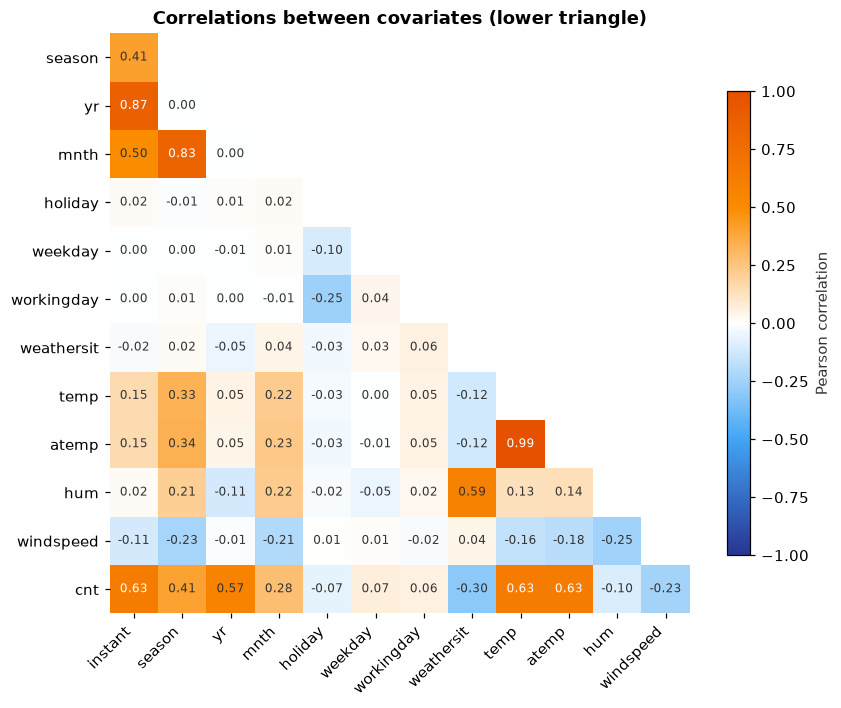

In [5]:
from matplotlib.colors import LinearSegmentedColormap

# Covariates only: remove the index, target and its two components (exact leakage)
covariates = daily.select_dtypes(include="number").drop(columns=["casual", "registered"])
corr = covariates.corr()  # Pearson correlation

# Strict lower triangle: mask the diagonal (always 1) and the upper triangle (redundant)
mask = np.triu(np.ones_like(corr, dtype=bool))
corr_tri = corr.mask(mask).iloc[1:, :-1]  # remove the empty first row and last column

# Diverging brand palette: dark blue (−1) → white (0) → orange (+1)
cmap = LinearSegmentedColormap.from_list(
    "palette", [PALETTE["darkblue"], PALETTE["blue"], "#FFFFFF", PALETTE["orange"], "#E65100"])
cmap.set_bad("white")  # masked cells in white

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(np.ma.masked_invalid(corr_tri.to_numpy()), cmap=cmap, vmin=-1, vmax=1)
for i in range(corr_tri.shape[0]):
    for j in range(corr_tri.shape[1]):
        v = corr_tri.iat[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{0.0 if abs(v) < 0.005 else v:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(v) > 0.6 else "#333333")
ax.set_xticks(range(corr_tri.shape[1]), corr_tri.columns, rotation=45, ha="right")
ax.set_yticks(range(corr_tri.shape[0]), corr_tri.index)
ax.grid(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
ax.set_title("Correlations between covariates (lower triangle)")
plt.tight_layout()
plt.show()

<div style="border-left:4px solid #FB8C00;padding:8px 14px;background:#FFF8E1;color:#000000">

**Question 1.3 — Plot the series**

Plot the observed series <code style="color:#000000;background:transparent">cnt</code> against the date. What do you observe?

</div>

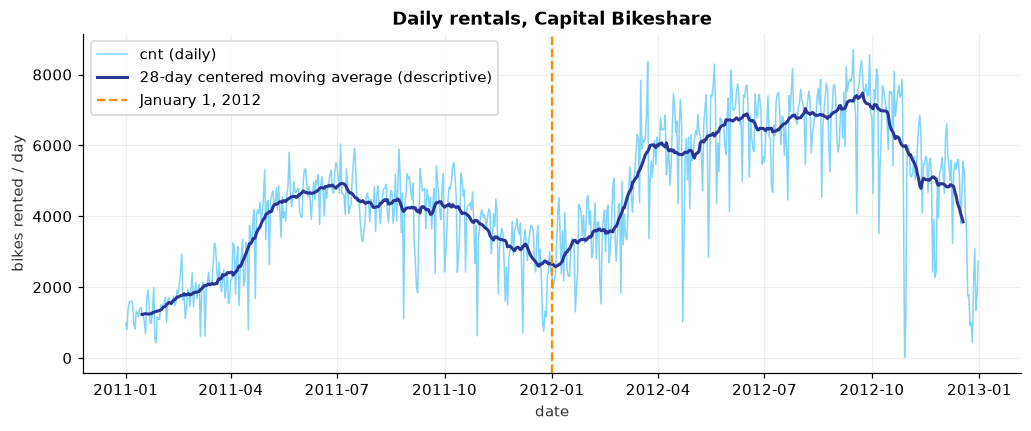

Minimum: 22 bikes on 2012-10-29


In [6]:
fig, ax = plt.subplots()
ax.plot(daily["dteday"], daily["cnt"], color=PALETTE["skyblue"], lw=1, label="cnt (daily)")
ax.plot(daily["dteday"], daily["cnt"].rolling(28, center=True).mean(), color=PALETTE["darkblue"],
        label="28-day centered moving average (descriptive)")
ax.axvline(pd.Timestamp("2012-01-01"), color=PALETTE["orange"], ls="--", lw=1.5, label="January 1, 2012")
ax.set(title="Daily rentals, Capital Bikeshare", xlabel="date", ylabel="bikes rented / day")
ax.legend(loc="upper left")
plt.show()

i_min = daily["cnt"].idxmin()
print(f"Minimum: {daily.loc[i_min, 'cnt']} bikes on {daily.loc[i_min, 'dteday'].date()}")

**Answer.**

1. **Upward trend:** 2012 is clearly above 2011 (network growth). The series is **not stationary**.
2. **Annual seasonality:** a trough in winter, a peak from May to September.
3. **High daily variability** around this seasonal pattern (weather, day of the week, public holidays).
4. **Isolated extreme values:** a few very low days, including the minimum in late October 2012
   (Hurricane Sandy). Squared loss will be highly sensitive to these.

The **centered** moving average uses the future (see the reminder in the introduction): it is reserved for description and must never be used for forecasting.
The orange dotted line anticipates the training set (2011) / test set (2012) split in Part 2: the test set will be **higher** than the training set,
a real challenge for any model.

### The covariates in `day.csv` at a glance

| Column | Description |
|:--|:--|
| `instant` | Row index, from 1 to 731. |
| `dteday` | Calendar date of the observation. |
| `season` | Season: 1 = winter, 2 = spring, 3 = summer, 4 = autumn. |
| `yr` | Year: 0 = 2011, 1 = 2012. |
| `mnth` | Month, from 1 to 12. |
| `holiday` | 1 if the day is a public holiday, 0 otherwise. |
| `weekday` | Day of the week, from 0 (Sunday) to 6 (Saturday). |
| `workingday` | 1 if the day is neither a weekend nor a public holiday, 0 otherwise. |
| `weathersit` | Weather conditions, from 1 (clear) to 4 (heavy rain, snow, thunderstorm). Used on day $t$, encoded as indicator variables (reference: 1). |
| `temp` | UCI-normalized temperature (reference scale: 41 °C), kept in $[0,1]$ and assumed known on day $t$. |
| `atemp` | Feels-like temperature in °C, divided by 50 (the maximum). |
| `hum` | Relative humidity, divided by 100. |
| `windspeed` | UCI-normalized wind speed (reference scale: 67 km/h), kept in $[0,1]$ and assumed known on day $t$. |
| `casual` | Number of rentals by casual users (non-subscribers). |
| `registered` | Number of rentals by subscribers. |
| `cnt` | Total rentals, `casual` + `registered`: **the target**. |

# Part 2 — Online learning

## 2.1 Protocol and regret

We play a repeated game against nature. On each day $t = 1, 2, \dots, T$:

1. we observe the covariates $\mathbf x_t \in \mathbb R^d$, all known **before** the decision;
2. we choose a parameter $\theta_t \in \mathcal K$ and predict $\widehat y_t = \mathbf x_t^\top \theta_t$ (or order a quantity $q_t$);
3. demand $y_t$ is revealed and we incur the loss $\ell_t(\theta_t)$;
4. we update: $\theta_{t+1} = \Pi_{\mathcal K}\big(\theta_t - \eta_t\, g_t\big)$ with $g_t \in \partial \ell_t(\theta_t)$.

**Available information.** The covariates include calendar variables, demand lags, and
the day's weather (`temp`, `weathersit`, `windspeed`), assumed observable at step 1.
The weather values are therefore **not lagged**; only demand is used with strictly positive lags.

This is **projected Online Gradient Descent** (OGD). For the ball $\mathcal K = \{\theta : \|\theta\|_2 \le B\}$, the projection is explicit:
$\Pi_{\mathcal K}(z) = z \cdot \min\{1,\ B/\|z\|_2\}$.

We measure performance using **regret**: the difference between our cumulative loss and that of the best **fixed** parameter selected in hindsight,
$$
R_T \;=\; \sum_{t=1}^T \ell_t(\theta_t) \;-\; \min_{u \in \mathcal K} \sum_{t=1}^T \ell_t(u).
$$
No probabilistic assumptions are made about $(y_t)$: the sequence can be arbitrary, or even adversarial.
An algorithm is *no-regret* if $R_T/T \to 0$: on average, it asymptotically performs as well as the best fixed choice.

## 2.2 Two model families

**(i) Squared loss: OGD and OGD + Ridge** (slides 53–59).

| | Loss | Gradient | Update | Guarantee |
|:--|:--|:--|:--|:--|
| OGD | $\ell_t(\theta) = \tfrac12(\mathbf x_t^\top\theta - y_t)^2$ | $e_t\,\mathbf x_t$, with $e_t = \widehat y_t - y_t$ | $\Pi_{\mathcal K}(\theta_t - \eta\, e_t \mathbf x_t)$ | $R_T \le D\,G\,\sqrt T$ for $\eta = \frac{D}{G\sqrt T}$ |
| OGD + Ridge | $\widetilde\ell_t(\theta) = \ell_t(\theta) + \tfrac{\lambda}{2}\|\theta\|_2^2$ | $e_t\,\mathbf x_t + \lambda\theta$ | $\Pi_{\mathcal K}\big((1-\eta_t\lambda)\theta_t - \eta_t\, e_t \mathbf x_t\big)$ | $\widetilde R_T \le \frac{G_\lambda^2}{2\lambda}(1+\log T)$ for $\eta_t = \frac{1}{\lambda t}$ |

with $D = 2B$ (diameter of $\mathcal K$), $G = (RB+Y)R$, and $G_\lambda = G + \lambda B$.

- **OGD:** the residual determines the sign and magnitude of the update, while $\mathbf x_t$ gives its direction. The loss is convex
  but its Hessian $\mathbf x_t\mathbf x_t^\top$ has rank 1, so there is no strong convexity and regret scales as $\sqrt T$.
- **Ridge:** the Hessian becomes $\mathbf x_t\mathbf x_t^\top + \lambda I_d \succeq \lambda I_d$. The loss is $\lambda$-strongly convex
  in **all** directions, hence logarithmic regret. Caution: this guarantee applies to the **regularized** loss
  $\widetilde\ell_t$, not to squared error alone.

**(ii) Newsvendor loss: ordering before demand is known** (slides 60–64).

We order $q_t \in [0, Q_{\max}]$ before observing $y_t$. Each excess bicycle costs $c_h$, and each missing bicycle costs $c_b$:
$$
\ell_t(q) = c_h\,(q - y_t)_+ + c_b\,(y_t - q)_+ = (c_b + c_h)\,\rho_\tau(y_t - q),
\qquad \tau = \frac{c_b}{c_b + c_h},
$$
where $\rho_\tau(r) = \tau r_+ + (1-\tau)(-r)_+$ is the *pinball* loss. A subgradient is $g_t = c_h$ for excess inventory ($q_t > y_t$),
$g_t = -c_b$ for a stockout ($q_t < y_t$), and $0$ for equality. Hence the rule: **stockout → increase, excess inventory → decrease**,
asymmetrically. With $\eta = Q_{\max}/(G\sqrt T)$ and $G = \max(c_b, c_h)$, we have $R_T \le Q_{\max}\, G\, \sqrt T$.

**Key result:** for demand with distribution $F$, the expected cost is minimized at the **critical quantile** $q^\star = F^{-1}(\tau)$.
On a sample, the best constant order quantity is the empirical $\tau$-quantile. We will verify this numerically.

The dataset provides **no** costs: we **set** $c_b = 3$ and $c_h = 1$ (a missing bicycle means losing a rental,
which is three times as costly as an idle bicycle), giving $\tau = 0{,}75$, as in the course. We will also test a
**contextual** version $q_t = \mathbf x_t^\top\theta_t$, which learns a conditional quantile using the same subgradient multiplied by $\mathbf x_t$.

<div style="border-left:4px solid #FB8C00;padding:8px 14px;background:#FFF8E1;color:#000000">

**Question 2.1 — Do the assumptions hold?**

Regret guarantees rely on assumptions. For each one, ask yourself **why** it is used in the proof and **how** to ensure it holds for our data: is the domain $\mathcal K$ convex and compact? Are the covariates bounded, $\|\mathbf x_t\|_2 \le R$? Is the target bounded, $|y_t| \le Y$? Are the losses convex? Which assumptions are **not** necessary?

</div>

**Answer.**

| Assumption | Role in the proof | In this practical |
|:--|:--|:--|
| $\mathcal K$ convex, closed, bounded, nonempty | the projection exists and brings us closer to every $u \in \mathcal K$; the diameter $D$ is finite | ball $\{\|\theta\|_2 \le B\}$ with $B = 2$, hence $D = 4$; for Newsvendor (no covariates), $[0, Q_{\max}]$ and $D = Q_{\max}$ |
| $\|\mathbf x_t\|_2 \le R$ | bounds the gradients | **by construction**: intercept $=1$; calendar: sum of squares $\le 1$; $\sin^2+\cos^2=1$; temperature and wind speed: each in $[0,1]$; weather indicators: sum of squares $\le 1$; $p$ lags in $[0,1]$, hence $R = \sqrt{p+6} = \sqrt{13}$ for $p=7$ |
| $\mid y_t\mid \le Y$ | bounds the residual, hence the gradient | $y_t = \texttt{cnt}_t / 10\,000 \in [0,1]$, hence $Y = 1$ |
| $\ell_t$ convex | convexity inequality, the core of the proof | squared loss: convex; ridge: $\lambda$-strongly convex; newsvendor: convex, piecewise linear, nondifferentiable (we use a subgradient) |
| known horizon $T$ | for the constant step size $\eta^\star = D/(G\sqrt T)$ | $T$ = window size; otherwise we would use $\eta_t \propto 1/\sqrt t$ |

**Points to watch.**

- The bounds $B$, $R$, and $Y$ are **specified a priori**, not estimated on the test set. The scale $10\,000$ is not the observed maximum: it is a plausible capacity.
  If future demand exceeded $10\,000$, the theorem would no longer apply. This should be reported, not silently clipped.
- The day's weather is **assumed known before the decision**, unlike the day's demand. This is not a property
  guaranteed by the CSV: in practice, unavailable daily aggregates would have to be replaced with forecasts.
- If $B$ is too small, it restricts the comparator, making low regret easy to achieve but uninformative. If $B$ is too large, it worsens the bound through $D$ and $G$.
- **Not needed:** independence, stationarity, a generative model. This is the strength of the online framework, and it is useful here because the series has a trend.
- A regret bound compares against the best **fixed** parameter. It promises neither a small absolute error nor good tracking of drifting demand.

In [7]:
P = 7                      # number of demand lags used as covariates
TARGET_SCALE = 10_000.0    # scale specified a priori: y = cnt / 10 000 ∈ [0, 1]
B = 2.0                    # radius of K = {θ : ||θ||₂ ≤ B}
C_B, C_H = 3.0, 1.0        # assumed costs: a stockout is 3× as costly as excess inventory
TAU = C_B / (C_B + C_H)    # critical quantile = 0.75
Q_MAX = 1.0                # newsvendor capacity: 10 000 bikes in normalized units

WEATHER_LEVELS = (1, 2, 3, 4)  # categories fixed a priori; category 1 = reference
# ||x_t||² ≤ 1 (intercept) + 1 (calendar) + 1 (sin² + cos²)
#             + 1 (temp) + 1 (windspeed) + 1 (weather indicators) + P (lags)
R = np.sqrt(P + 6)
Y = 1.0
D = 2 * B
G_SQ = (R * B + Y) * R     # gradient bound for the squared loss on K
G_NV = max(C_B, C_H)       # newsvendor with no covariates
G_CTX = max(C_B, C_H) * R  # contextual newsvendor


def theory_table(T):
    """Theoretical step sizes and average regret bounds R_T / T, for a horizon T."""
    rows = {
        "OGD (squared loss)": (D, G_SQ),
        "Newsvendor (no covariates)": (Q_MAX, G_NV),
        "Newsvendor (contextual)": (D, G_CTX),
    }
    return pd.DataFrame({name: {"D": d, "G": g, "η* = D/(G√T)": d / (g * np.sqrt(T)),
                                "bound R_T/T = DG/√T": d * g / np.sqrt(T)}
                         for name, (d, g) in rows.items()}).T.round(4)


print(f"R = {R:.3f}, Y = {Y}, B = {B}, τ = {TAU}")
print(f"Bounds verified a posteriori: max cnt / scale = {daily['cnt'].max() / TARGET_SCALE:.3f} ≤ Y = {Y}")
display(theory_table(T=365))
for lam in [0.01, 0.1]:
    G_lam = G_SQ + lam * B
    print(f"Ridge λ = {lam:<5}: bound R̃_T/T = G_λ²(1 + log T)/(2λT) = {G_lam**2 * (1 + np.log(365)) / (2 * lam * 365):.2f}")

R = 3.606, Y = 1.0, B = 2.0, τ = 0.75
Bounds verified a posteriori: max cnt / scale = 0.871 ≤ Y = 1.0


,D,G,η* = D/(G√T),bound R_T/T = DG/√T
OGD (squared loss),4.0,29.6056,0.0071,6.1985
Newsvendor (no covariates),1.0,3.0000,0.0174,0.1570
Newsvendor (contextual),4.0,10.8167,0.0194,2.2647


Ridge λ = 0.01 : bound R̃_T/T = G_λ²(1 + log T)/(2λT) = 829.57
Ridge λ = 0.1  : bound R̃_T/T = G_λ²(1 + log T)/(2λT) = 83.97


## Remark — bound on average regret for Ridge

For OGD on the regularized loss, with the **theoretical step size** $\eta_t=1/(\lambda t)$ and $\lambda>0$:

$$
\frac{\widetilde R_T}{T}
\le \frac{(G+\lambda B)^2(1+\log T)}{2\lambda T},
\qquad G=(RB+Y)R.
$$

Here $R=\sqrt{p+6}$ incorporates the three weather variables. For any fixed $\lambda>0$, this bound tends to zero as $T$ grows.
For a fixed horizon, its minimum over $\lambda$ is attained at $\lambda^\star=G/B$ (we minimize $G^2/\lambda+2GB+B^2\lambda$).
**Minimizing this pessimistic bound does not guarantee minimizing the realized regret or RMSE**:
predictive hyperparameters are still selected using only the training set.

The plot below shows this **reference bound**, with the illustrative horizon $T=365$.
The learning code caps the step size at $1/R^2$: the initial phase changes the constant in the guarantee;
the displayed formula is therefore not an exact finite-horizon bound for this capped variant without an additional term.


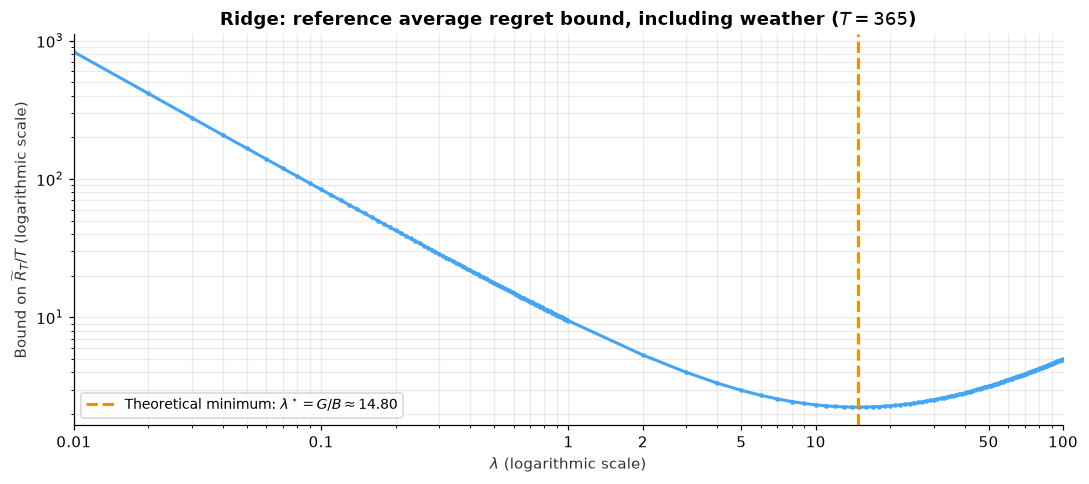

In [8]:
# Theoretical Ridge average regret bound, not a gradient bound.
T_bound = 365

# 0.01, 0.02, ..., 1.00, then 2, 3, ..., 100: 199 values, with no duplicates.
lambdas = np.concatenate([
    np.arange(1, 101) / 100.0,
    np.arange(2, 101, dtype=float),
])
gradient_bounds = G_SQ + lambdas * B
mean_regret_bounds = (
    gradient_bounds**2 * (1 + np.log(T_bound))
    / (2 * lambdas * T_bound)
)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(lambdas, mean_regret_bounds, marker=".", markersize=4, color=PALETTE["blue"])
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(0.01, 100)
ax.set_xticks([0.01, 0.1, 1, 2, 5, 10, 50, 100], ["0.01", "0.1", "1", "2", "5", "10", "50", "100"])
ax.set_xlabel(r"$\lambda$ (logarithmic scale)")
ax.set_ylabel(r"Bound on $\widetilde{R}_T/T$ (logarithmic scale)")
ax.set_title(
    rf"Ridge: reference average regret bound, including weather ($T={T_bound}$)"
)
lambda_opt_bound = G_SQ / B
ax.axvline(lambda_opt_bound, color=PALETTE["orange"], ls="--",
           label=rf"Theoretical minimum: $\lambda^\star=G/B \approx {lambda_opt_bound:.2f}$")
ax.legend(fontsize=9)
ax.grid(True, which="both", alpha=0.25)
plt.tight_layout()
plt.show()


The bounds are **very pessimistic**: an average regret bound of order one is enormous compared with squared losses
of order $10^{-3}$ in normalized units. The ridge bound is even unusable for small $\lambda$, because of the factor $1/\lambda$.
These are **worst-case** guarantees, valid for any sequence, not performance forecasts. The theoretical step size $\eta^\star$
is nevertheless included in the grid tested below.

<div style="border-left:4px solid #FB8C00;padding:8px 14px;background:#FFF8E1;color:#000000">

**Question 2.2 — Prepare the covariates**

For each day $t$, construct a vector $\mathbf x_t = (1, \mathbf z_t, y_{t-1}, \dots, y_{t-p})$ containing only information available **before** observing $y_t$. Here $\mathbf z_t$ comprises the calendar variables and the day's weather variables **temp**, **weathersit**, **windspeed**, assumed known before the decision. Encode weather conditions using indicator variables and retain the normalized temperature and wind speed scales. The learned parameter is $\theta_t$, and we predict $\widehat y_t = \mathbf x_t^\top\theta_t$. Which columns must be excluded, and why? Verify numerically that $\|\mathbf x_t\|_2 \le R$ and that the covariates are causal.

</div>

**Selected choices.**

- **Calendar:** `workingday`, `holiday`, $\sin(2\pi j_t/365{,}25)$, and $\cos(2\pi j_t/365{,}25)$,
  where $j_t$ is the day of the year. The two calendar indicators cannot both equal 1.
- **Weather on day $t$, assumed known before the prediction:**
  - `temp` and `windspeed` remain on their UCI scales in $[0,1]$; no normalization is learned on the test set;
  - `weathersit` is a **category**, not a continuous quantity: we create the indicators
    `weathersit_2`, `weathersit_3`, `weathersit_4`, with category 1 as the reference.
    The possible categories 1 to 4 are fixed a priori, even if one is absent from the training set.
    At most one of these three indicators equals 1, so their contribution to the squared norm is at most 1.
- **Demand lags:** only $y_{t-1},\dots,y_{t-7}$. Weather is not lagged under our assumption;
  demand $y_t$ is never included among the day's covariates.
- **Excluded:** `casual` and `registered` (exact target leakage); `instant` (trend not bounded a priori);
  `hum` and `atemp`, not included in this variant. No future observation is used.
- With the intercept, there are $d=p+10=17$ columns. The first $p=7$ days provide the history: 724 usable days remain.
  The deterministic bound is $R^2=1+1+1+1+1+1+p=p+6=13$, hence $R=\sqrt{13}$.

**Scope of the weather assumption.** The observed daily aggregates in the CSV would generally not be available before
a decision made at the start of the day. Using them here is permitted by the explicit assumption in this practical;
a real-world application requires weather forecasts available at the time of the decision.


In [9]:
def build_features(frame, p=P, scale=TARGET_SCALE):
    """Calendar and weather known on day t; only demand lags use the past."""
    weather = frame[["temp", "windspeed"]].to_numpy(dtype=float)
    if not (np.isfinite(weather).all() and ((0 <= weather) & (weather <= 1)).all()):
        raise ValueError("temp and windspeed must be finite and normalized to [0, 1].")
    if not frame["weathersit"].isin(WEATHER_LEVELS).all():
        raise ValueError("weathersit must be one of the categories 1, 2, 3, 4.")

    y_all = frame["cnt"].to_numpy(dtype=float) / scale
    angle = 2 * np.pi * frame["dteday"].dt.day_of_year.to_numpy() / 365.25
    feats = pd.DataFrame({
        "intercept": 1.0,
        "workingday": frame["workingday"].astype(float),
        "holiday": frame["holiday"].astype(float),
        "temp": frame["temp"].astype(float),
        "windspeed": frame["windspeed"].astype(float),
        "sin_annual": np.sin(angle),
        "cos_annual": np.cos(angle),
    }, index=frame.index)
    # Encoding fixed without consulting the training set or test set; category 1 = reference.
    for level in WEATHER_LEVELS[1:]:
        feats[f"weathersit_{level}"] = frame["weathersit"].eq(level).astype(float)
    for k in range(1, p + 1):
        feats[f"y_lag{k}"] = pd.Series(y_all, index=frame.index).shift(k)
    keep = feats.notna().all(axis=1).to_numpy()  # incomplete history: the first p days
    return (feats.loc[keep].to_numpy(dtype=float), y_all[keep],
            frame.loc[keep, "dteday"].reset_index(drop=True), list(feats.columns))


X, y, dates, feature_names = build_features(daily)
print("Today's weather known before the decision: temp, weathersit (indicators), windspeed.")
print("X :", X.shape, " y :", y.shape, " from", dates.iloc[0].date(), "to", dates.iloc[-1].date())
display(pd.DataFrame(X[:5], columns=feature_names, index=dates[:5].dt.date).round(3))


Today's weather known before the decision: temp, weathersit (indicators), windspeed.
X : (724, 17)  y : (724,)  from 2011-01-08 to 2012-12-31


,intercept,workingday,holiday,temp,windspeed,sin_annual,cos_annual,weathersit_2,weathersit_3,weathersit_4,y_lag1,y_lag2,y_lag3,y_lag4,y_lag5,y_lag6,y_lag7
dteday,,,,,,,,,,,,,,,,,
2011-01-08,1.0,0.0,0.0,0.165,0.267,0.137,0.991,1.0,0.0,0.0,0.151,0.161,0.160,0.156,0.135,0.080,0.098
2011-01-09,1.0,0.0,0.0,0.138,0.362,0.154,0.988,0.0,0.0,0.0,0.096,0.151,0.161,0.160,0.156,0.135,0.080
2011-01-10,1.0,1.0,0.0,0.151,0.223,0.171,0.985,0.0,0.0,0.0,0.082,0.096,0.151,0.161,0.160,0.156,0.135
2011-01-11,1.0,1.0,0.0,0.169,0.122,0.188,0.982,1.0,0.0,0.0,0.132,0.082,0.096,0.151,0.161,0.160,0.156
2011-01-12,1.0,1.0,0.0,0.173,0.305,0.205,0.979,0.0,0.0,0.0,0.126,0.132,0.082,0.096,0.151,0.161,0.160


In [10]:
# 1) Deterministic bounds: calendar categories are mutually exclusive, weather is normalized.
assert daily[["workingday", "holiday"]].isin([0, 1]).all().all()
assert (daily["workingday"] + daily["holiday"] <= 1).all()
norms = np.linalg.norm(X, axis=1)
assert np.isfinite(X).all() and np.isfinite(y).all()
assert np.all(norms <= R + 1e-12), "The stated norm bound is exceeded."
assert np.all(np.abs(y) <= Y), "The target exceeds the specified scale: report this exceedance."
print(f"max_t ||x_t||₂ = {norms.max():.3f} ≤ R = {R:.3f} : True")
print(f"max_t |y_t|    = {np.abs(y).max():.3f} ≤ Y = {Y} : True")

# 2) All three weather variables are included on day t, without a lag.
for col in ["temp", "windspeed"]:
    np.testing.assert_allclose(X[:, feature_names.index(col)], daily[col].iloc[P:])
for level in WEATHER_LEVELS[1:]:
    np.testing.assert_array_equal(
        X[:, feature_names.index(f"weathersit_{level}")],
        daily["weathersit"].iloc[P:].eq(level).to_numpy(dtype=float),
    )
print("Alignment verified: weather on day t, demand lags strictly from the past.")

# 3) Changing y_t0 does not change any covariates for days ≤ t0.
t0 = 300
row_t0 = t0 - P
perturbed = daily.copy()
perturbed.loc[t0, "cnt"] += 5_000
X_pert, *_ = build_features(perturbed)
np.testing.assert_array_equal(X[:row_t0 + 1], X_pert[:row_t0 + 1])
assert not np.array_equal(X[row_t0 + 1], X_pert[row_t0 + 1])
print("No target leakage verified: y_t0 only affects lags for subsequent days.")

# 4) Changing all future weather and demand must not affect days ≤ t0.
future = daily.copy()
future.loc[t0 + 1:, "cnt"] = 0
for col in ["temp", "windspeed"]:
    future.loc[t0 + 1:, col] = 1 - future.loc[t0 + 1:, col]
future.loc[t0 + 1:, "weathersit"] = future.loc[t0 + 1:, "weathersit"] % 4 + 1
X_future, *_ = build_features(future)
np.testing.assert_array_equal(X[:row_t0 + 1], X_future[:row_t0 + 1])
print("No future leakage verified, including for weather variables.")


max_t ||x_t||₂ = 2.959 ≤ R = 3.606 : True
max_t |y_t|    = 0.871 ≤ Y = 1.0 : True
Alignment verified: weather on day t, demand lags strictly from the past.
No target leakage verified: y_t0 only affects lags for subsequent days.
No future leakage verified, including for weather variables.


<div style="border-left:4px solid #FB8C00;padding:8px 14px;background:#FFF8E1;color:#000000">

**Question 2.3 — Training then testing, predicting before learning**

Split the data chronologically: **training set = 2011**, **test set = 2012**. Write an online loop that, each day, **predicts first** and then updates using $y_t$. How can the hyperparameters be chosen without looking at the test set? Should the model continue learning on the test set? Finally, plot the time series again, coloring the training set and test set windows.

</div>

**Answer: four rules.**

1. **Predict, then learn.** The prediction for day $t$ is computed **before** $y_t$ is revealed. Updating first
   and then predicting would amount to cheating: we would be evaluating a model that has already seen the answer. We store a **copy**
   of the parameter $\theta_t$ that was actually used, because otherwise the next update would modify it through aliasing.
2. **Split by date, without random shuffling.** We want to predict the future from the past: shuffling the days would
   leak information from 2012 into 2011.
3. **Hyperparameters chosen on the training set only.** For each value in a small grid, we run the online algorithm
   on 2011 and retain the value yielding the lowest average loss. It is then **fixed**: we do not go back after seeing the test set.
4. **On the test set, learning continues.** This is the principle of online learning: the model starts from its end-of-2011 state,
   without resetting the clock $t$, and each prediction in 2012 is made before the demand is revealed. This
   *prequential* evaluation sees no future demand: it uses past demand and, by assumption, the current day's weather, known before the decision.

In [11]:
is_train = (dates < "2012-01-01").to_numpy()
X_train, y_train, dates_train = X[is_train], y[is_train], dates[is_train]
X_test, y_test, dates_test = X[~is_train], y[~is_train], dates[~is_train].reset_index(drop=True)
print(f"Training set: {len(y_train)} days ({dates_train.iloc[0].date()} → {dates_train.iloc[-1].date()})")
print(f"Test set: {len(y_test)} days ({dates_test.iloc[0].date()} → {dates_test.iloc[-1].date()})")


def run_online(model, X, y):
    """Online loop: each day, (1) predict with θ_t, (2) reveal y_t, (3) update."""
    preds = np.empty(len(y))
    params = []
    for t in range(len(y)):
        params.append(np.copy(model.params()))  # copy of the parameter ACTUALLY used to predict
        preds[t] = model.predict(X[t])          # 1) prediction BEFORE observing y_t
        model.update(X[t], y[t])                # 2) y_t revealed → correction
    return preds, np.array(params)


def squared_loss(pred, y):
    return 0.5 * (pred - y) ** 2


def newsvendor_loss(q, y, c_b=C_B, c_h=C_H):
    return c_h * np.maximum(q - y, 0.0) + c_b * np.maximum(y - q, 0.0)


def select_on_train(make_model, grid, loss):
    """Average online loss on the training set for each hyperparameter; returns the best (first in case of a tie)."""
    scores = pd.Series({h: loss(run_online(make_model(h), X_train, y_train)[0], y_train).mean() for h in grid})
    return scores.idxmin(), scores


def train_then_test(make_model, h):
    """Learns online on 2011, then continues on 2012, recording test set predictions."""
    model = make_model(h)
    run_online(model, X_train, y_train)      # training set window
    return run_online(model, X_test, y_test)  # test set window (predict then learn)


results = {}  # model name → test set predictions and parameters

Training set: 358 days (2011-01-08 → 2011-12-31)
Test set: 366 days (2012-01-01 → 2012-12-31)


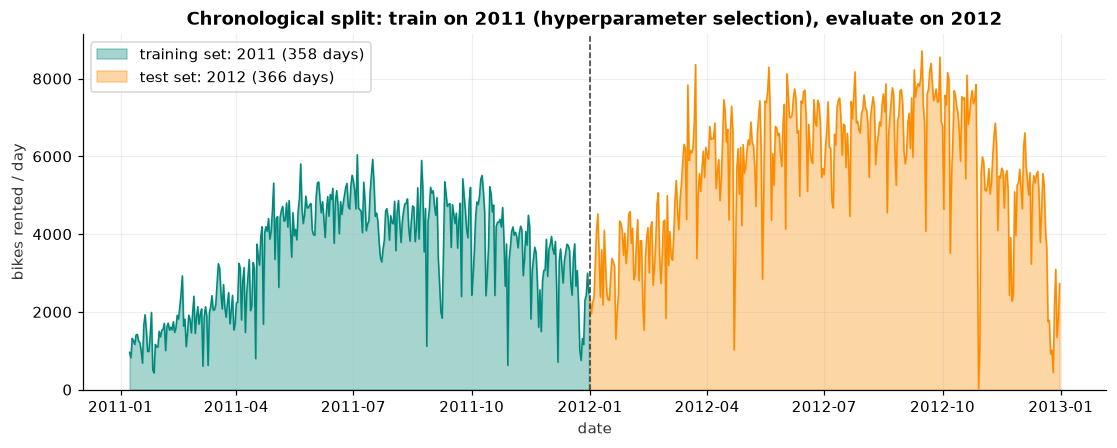

In [12]:
counts = y * TARGET_SCALE
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.fill_between(dates[is_train], 0, counts[is_train], color=PALETTE["teal"], alpha=0.35,
                label=f"training set: 2011 ({is_train.sum()} days)")
ax.fill_between(dates[~is_train], 0, counts[~is_train], color=PALETTE["orange"], alpha=0.35,
                label=f"test set: 2012 ({(~is_train).sum()} days)")
ax.plot(dates[is_train], counts[is_train], color=PALETTE["teal"], lw=1)
ax.plot(dates[~is_train], counts[~is_train], color=PALETTE["orange"], lw=1)
ax.axvline(pd.Timestamp("2012-01-01"), color="#333333", ls="--", lw=1)
ax.set_ylim(bottom=0)
ax.set(title="Chronological split: train on 2011 (hyperparameter selection), evaluate on 2012",
       xlabel="date", ylabel="bikes rented / day")
ax.legend(loc="upper left")
plt.show()

**Interpretation.** The split follows the arrow of time: nothing from the orange window is used to choose the hyperparameters.
The test set window is **higher and more variable** than the training set window. A model that simply reproduced the 2011 level
would consistently underestimate 2012: this is why online models continue updating on the test set.

## 2.4 Model (i-a) — OGD with squared loss

We start from $\theta_1 = 0 \in \mathcal K$ with a constant step size $\eta$, as in the theorem. The grid contains the theoretical step size
$\eta^\star = D/(G\sqrt{T_{\text{train}}})$ and larger step sizes. The theorem takes a worst-case perspective; in practice, a larger step size
often tracks changing demand better.

In [13]:
def project_ball(theta, radius=B):
    """Euclidean projection onto K = {θ : ||θ||₂ ≤ radius}."""
    norm = np.linalg.norm(theta)
    return theta if norm <= radius else theta * (radius / norm)


class OGD:
    """Projected OGD, squared loss ½(xᵀθ − y)², constant step size η."""

    def __init__(self, eta, d=X.shape[1], radius=B):
        self.eta, self.radius = eta, radius
        self.theta = np.zeros(d)

    def params(self):
        return self.theta

    def predict(self, x):
        return x @ self.theta

    def update(self, x, y):
        e = x @ self.theta - y                                                 # residual e_t
        self.theta = project_ball(self.theta - self.eta * e * x, self.radius)  # θ ← Π_K(θ − η e_t x_t)


# Loop causality test: changing y_t does not change the prediction for day t.
y_mod = y_test.copy()
y_mod[100] += 0.5
p_ref, _ = run_online(OGD(0.03), X_test, y_test)
p_mod, _ = run_online(OGD(0.03), X_test, y_mod)
assert np.allclose(p_ref[:101], p_mod[:101]) and not np.allclose(p_ref[101:], p_mod[101:])
print("Causal loop: the prediction for day t does not use y_t.")

eta_star = D / (G_SQ * np.sqrt(len(y_train)))
OGD_GRID = sorted({round(eta_star, 4), 0.003, 0.01, 0.03, 0.1, 0.3})
best_eta, scores = select_on_train(OGD, OGD_GRID, squared_loss)
display(scores.rename("average squared loss (training set 2011)").to_frame().style.format("{:.5f}"))
print(f"theoretical η* = {eta_star:.4f} ; η selected on the training set = {best_eta}")

pred, params = train_then_test(OGD, best_eta)
results["OGD"] = {"pred": pred, "params": params, "hyper": f"η = {best_eta}"}
print("Coefficients at the end of the test set:", dict(zip(feature_names, params[-1].round(3))))

Causal loop: the prediction for day t does not use y_t.


,average squared loss (training set 2011)
0.003000,0.01392
0.007100,0.00714
0.010000,0.00580
0.030000,0.00359
0.100000,0.00262
0.300000,0.00385


theoretical η* = 0.0071 ; η selected on the training set = 0.1
Coefficients at the end of the test set: {'intercept': np.float64(0.309), 'workingday': np.float64(0.072), 'holiday': np.float64(-0.038), 'temp': np.float64(0.194), 'windspeed': np.float64(-0.037), 'sin_annual': np.float64(0.108), 'cos_annual': np.float64(-0.182), 'weathersit_2': np.float64(-0.069), 'weathersit_3': np.float64(-0.255), 'weathersit_4': np.float64(0.0), 'y_lag1': np.float64(0.018), 'y_lag2': np.float64(-0.029), 'y_lag3': np.float64(-0.012), 'y_lag4': np.float64(0.007), 'y_lag5': np.float64(0.046), 'y_lag6': np.float64(0.082), 'y_lag7': np.float64(0.106)}


**Interpretation.** The theoretical step size is small: the guarantee covers the worst case, and a favorable sequence allows a larger step size.
The coefficients shown now correspond to calendar variables, temperature, wind, weather indicators, and demand lags.
Their importance must be assessed from the recomputed results, rather than assumed unchanged after adding variables.
If an excessively large step size destabilizes the algorithm, projection onto $\mathcal K$ prevents the coefficients from exploding:
this is one of the practical roles of the compact domain.

## 2.5 Model (i-b) — OGD + Ridge

We apply OGD to $\widetilde\ell_t(\theta) = \tfrac12(\mathbf x_t^\top\theta - y_t)^2 + \tfrac\lambda2\|\theta\|_2^2$. The update **shrinks** $\theta$ by a factor
$(1 - \eta_t\lambda)$, then corrects in the direction $\mathbf x_t$. The clock $t$ **is not reset** at the start of the test set.

**The step size.** The course uses $\eta_t = 1/(\lambda t)$. For small $\lambda$, the initial step sizes are enormous ($\eta_1 = 1/\lambda$): as long as
$\eta_t\|\mathbf x_t\|^2 > 2$, a correction overshoots its target and the algorithm bounces off the boundary of $\mathcal K$. With $\|\mathbf x_t\|^2 \le R^2$,
this lasts until $t \approx R^2/(2\lambda)$ days: more than 2 100 days with $R^2=13$ and $\lambda = 0{,}003$, that is, the entire series. We therefore **cap** the step size:
$$
\eta_t = \min\Big\{\eta_{\max},\ \frac{1}{\lambda t}\Big\}, \qquad \eta_{\max} = \frac{1}{R^2},
$$
a cap fixed **a priori** from the bound $R$ in Question 2.1. As soon as $t \ge R^2/\lambda$, we recover exactly the step size from the course;
the cap adds only a constant term to the $\log T$ bound. For small $\lambda$, the capped phase covers the entire series:
OGD + Ridge then behaves like OGD with step size $1/R^2$ and slight shrinkage.

We choose $\lambda$ on the training set using the **unpenalized** squared error, since prediction quality is what matters to us.
The regret in Part 3, however, will be computed using the **penalized** loss, the one in the theorem.

In [14]:
class OGDRidge(OGD):
    """Projected OGD on the ridge loss ½(xᵀθ − y)² + λ/2 ||θ||², step size η_t = min(1/R², 1/(λ t))."""

    def __init__(self, lam, d=X.shape[1], radius=B, eta_max=1 / R**2):
        super().__init__(eta=None, d=d, radius=radius)
        self.lam, self.eta_max, self.t = lam, eta_max, 0

    def update(self, x, y):
        self.t += 1
        eta = min(self.eta_max, 1.0 / (self.lam * self.t))
        e = x @ self.theta - y
        self.theta = project_ball((1 - eta * self.lam) * self.theta - eta * e * x, self.radius)


RIDGE_GRID = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]
best_lam, scores = select_on_train(OGDRidge, RIDGE_GRID, squared_loss)
display(scores.rename("average squared loss (training set 2011)").to_frame().style.format("{:.5f}"))
print(f"η_max = 1/R² = {1 / R**2:.3f} ; λ selected on the training set = {best_lam} "
      f"(course step size 1/(λt) reached from t = {R**2 / best_lam:.0f})")

pred, params = train_then_test(OGDRidge, best_lam)
results["OGD + Ridge"] = {"pred": pred, "params": params, "hyper": f"λ = {best_lam}", "lam": best_lam}
print("Coefficients at the end of the test set:", dict(zip(feature_names, params[-1].round(3))))
print(f"||θ|| at the end of the test set: Ridge = {np.linalg.norm(params[-1]):.3f}, "
      f"OGD = {np.linalg.norm(results['OGD']['params'][-1]):.3f}")

,average squared loss (training set 2011)
0.001000,0.00275
0.003000,0.00275
0.010000,0.00276
0.030000,0.00281
0.100000,0.00310
0.300000,0.00415


η_max = 1/R² = 0.077 ; λ selected on the training set = 0.001 (course step size 1/(λt) reached from t = 13000)
Coefficients at the end of the test set: {'intercept': np.float64(0.279), 'workingday': np.float64(0.063), 'holiday': np.float64(-0.033), 'temp': np.float64(0.176), 'windspeed': np.float64(-0.022), 'sin_annual': np.float64(0.097), 'cos_annual': np.float64(-0.166), 'weathersit_2': np.float64(-0.068), 'weathersit_3': np.float64(-0.219), 'weathersit_4': np.float64(0.0), 'y_lag1': np.float64(0.066), 'y_lag2': np.float64(0.001), 'y_lag3': np.float64(0.002), 'y_lag4': np.float64(0.015), 'y_lag5': np.float64(0.045), 'y_lag6': np.float64(0.075), 'y_lag7': np.float64(0.089)}
||θ|| at the end of the test set: Ridge = 0.474, OGD = 0.526


**Interpretation.** Two effects counteract each other:

- **Small $\lambda$:** little shrinkage, and the capped phase lasts a long time. We obtain almost OGD with step size $1/R^2$.
- **Large $\lambda$:** we quickly reach the decreasing step size $1/(\lambda t)$. The coefficients are strongly shrunk toward 0, including the intercept,
  introducing a bias toward predictions that are too low, and the step size soon becomes too small to track growing demand.

Remove the cap (`eta_max=np.inf`) to see the behavior of the raw step size $1/(\lambda t)$ on the training set.
OGD + Ridge provides a $\log T$ guarantee, but for a **different objective**: this does not automatically mean better prediction under squared loss.

## 2.6 Model (ii) — Newsvendor loss

### Empirical verification: the optimum is the quantile $\tau = c_b/(c_b + c_h)$

Within the training set window, we compute the average cost $\frac1n\sum_t \ell_t(q)$ of a **constant** order $q$ over a fine grid,
and compare its minimizer with the empirical $\tau$-quantile of $(y_t)$. We repeat the experiment for several pairs $(c_b, c_h)$.

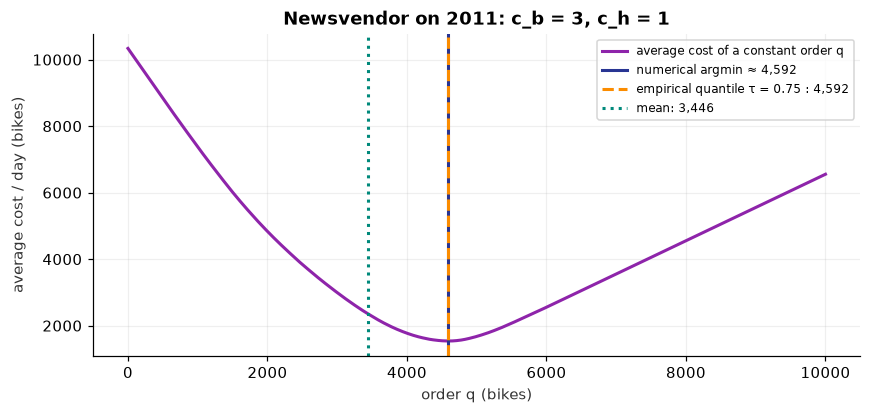

,c_b,c_h,τ,numerical argmin,empirical quantile
0,1,1,0.50,3750.0,3750.0
1,1,3,0.25,2210.0,2209.0
2,3,1,0.75,4592.0,4592.0
3,9,1,0.90,4990.0,4991.0


In [15]:
q_grid = np.linspace(0.0, Q_MAX, 4001)
cost = np.array([newsvendor_loss(q, y_train).mean() for q in q_grid])
q_argmin = q_grid[cost.argmin()]
q_quantile = np.quantile(y_train, TAU, method="inverted_cdf")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(q_grid * TARGET_SCALE, cost * TARGET_SCALE, color=PALETTE["purple"], label="average cost of a constant order q")
ax.axvline(q_argmin * TARGET_SCALE, color=PALETTE["darkblue"], lw=2, label=f"numerical argmin ≈ {q_argmin * TARGET_SCALE:,.0f}")
ax.axvline(q_quantile * TARGET_SCALE, color=PALETTE["orange"], ls="--", lw=2,
           label=f"empirical quantile τ = {TAU} : {q_quantile * TARGET_SCALE:,.0f}")
ax.axvline(y_train.mean() * TARGET_SCALE, color=PALETTE["teal"], ls=":", lw=2,
           label=f"mean: {y_train.mean() * TARGET_SCALE:,.0f}")
ax.set(title="Newsvendor on 2011: c_b = 3, c_h = 1", xlabel="order q (bikes)", ylabel="average cost / day (bikes)")
ax.legend(fontsize=8)
plt.show()

rows = []
for c_b, c_h in [(1, 1), (1, 3), (3, 1), (9, 1)]:
    tau = c_b / (c_b + c_h)
    c = np.array([newsvendor_loss(q, y_train, c_b, c_h).mean() for q in q_grid])
    rows.append({"c_b": c_b, "c_h": c_h, "τ": tau,
                 "numerical argmin": q_grid[c.argmin()] * TARGET_SCALE,
                 "empirical quantile": np.quantile(y_train, tau, method="inverted_cdf") * TARGET_SCALE})
display(pd.DataFrame(rows).round({"τ": 3, "numerical argmin": 0, "empirical quantile": 0}))

**Interpretation.** The numerical argmin coincides with the empirical $\tau$-quantile, up to the grid resolution. The cost is piecewise linear,
with kinks at the observed values. When $n\tau$ is an integer, the argmin is an entire **interval** between two observations: this is the condition
$F(q^{\star-}) \le \tau \le F(q^\star)$ from the course. With $c_b = c_h$, we recover the **median**. The more costly a stockout is, the more we order,
and ordering the **mean** is more expensive.

### OGD for Newsvendor (no covariates)

This is the algorithm from slides 63–64: $q_{t+1} = \Pi_{[0, Q_{\max}]}(q_t - \eta\, g_t)$. No covariates are used, but the order
$q_t$ **changes every day**: after a stockout, it increases by $\eta c_b$; with excess inventory, it decreases by $\eta c_h$. The **comparator**, by contrast, is a single
constant order chosen in hindsight: the clipped empirical quantile.

In [16]:
class NewsvendorOGD:
    """Order q_t ∈ [0, Q_max] with no covariates, learned by projected subgradient."""

    def __init__(self, eta, q0=0.0, q_max=Q_MAX):
        self.eta, self.q, self.q_max = eta, q0, q_max

    def params(self):
        return np.array([self.q])

    def predict(self, x):
        return self.q  # ignores covariates

    def update(self, x, y):
        g = C_H if self.q > y else (-C_B if self.q < y else 0.0)  # excess inventory: +c_h; stockout: −c_b
        self.q = float(np.clip(self.q - self.eta * g, 0.0, self.q_max))


eta_nv_star = Q_MAX / (G_NV * np.sqrt(len(y_train)))
NV_GRID = sorted({round(eta_nv_star, 4), 0.001, 0.003, 0.01, 0.03})
best_eta_nv, scores = select_on_train(NewsvendorOGD, NV_GRID, newsvendor_loss)
display(scores.rename("average newsvendor cost (training set 2011)").to_frame().style.format("{:.5f}"))
print(f"theoretical η* = {eta_nv_star:.4f} ; selected η = {best_eta_nv}")

pred, params = train_then_test(NewsvendorOGD, best_eta_nv)
results["Newsvendor (no covariates)"] = {"pred": pred, "params": params, "hyper": f"η = {best_eta_nv}"}
print(f"Frequency of days without a stockout in 2012, P(y_t ≤ q_t) = {np.mean(y_test <= pred):.3f} (target τ = {TAU})")

,average newsvendor cost (training set 2011)
0.001000,0.17730
0.003000,0.09053
0.010000,0.08073
0.017600,0.08117
0.030000,0.09265


theoretical η* = 0.0176 ; selected η = 0.01
Frequency of days without a stockout in 2012, P(y_t ≤ q_t) = 0.740 (target τ = 0.75)


### OGD for Newsvendor (contextual): a conditional quantile

We replace the order without covariates with $q_t = \mathbf x_t^\top\theta_t$, with $\theta_t \in \mathcal K$. The subgradient becomes
$g_t = \big(c_h\,\mathbf 1\{q_t > y_t\} - c_b\,\mathbf 1\{q_t < y_t\}\big)\,\mathbf x_t$. We thus learn a **conditional quantile**
at level $\tau$ that uses calendar information, the current day's weather, assumed known, and recent demand.

*Remark.* Nothing forces $q_t \in [0, Q_{\max}]$ for a linear model. We check this a posteriori; in deployment, we would clip the order.

In [17]:
class ContextualNewsvendorOGD(OGD):
    """q_t = x_tᵀθ_t, subgradient of the newsvendor loss, projection onto K."""

    def update(self, x, y):
        q = x @ self.theta
        g = C_H if q > y else (-C_B if q < y else 0.0)
        self.theta = project_ball(self.theta - self.eta * g * x, self.radius)


CTX_GRID = sorted({round(D / (G_CTX * np.sqrt(len(y_train))), 4), 0.0003, 0.001, 0.003, 0.01})
best_eta_ctx, scores = select_on_train(ContextualNewsvendorOGD, CTX_GRID, newsvendor_loss)
display(scores.rename("average newsvendor cost (training set 2011)").to_frame().style.format("{:.5f}"))
print(f"selected η = {best_eta_ctx}")

pred, params = train_then_test(ContextualNewsvendorOGD, best_eta_ctx)
results["Newsvendor (contextual)"] = {"pred": pred, "params": params, "hyper": f"η = {best_eta_ctx}"}
print(f"P(y_t ≤ q_t) in 2012 = {np.mean(y_test <= pred):.3f} (target τ = {TAU})")
print(f"Orders outside [0, Q_max]: {np.mean((pred < 0) | (pred > Q_MAX)):.1%} of days")

,average newsvendor cost (training set 2011)
0.000300,0.23907
0.001000,0.11457
0.003000,0.08855
0.010000,0.10310
0.019500,0.15477


selected η = 0.003
P(y_t ≤ q_t) in 2012 = 0.738 (target τ = 0.75)
Orders outside [0, Q_max]: 0.0% of days


## 2.7 Naive baselines

An algorithm is of value only in comparison with a simple baseline. We add two predictors that do not learn:
**Naive (previous day)** ($\widehat y_t = y_{t-1}$) and **Naive (previous week)** ($\widehat y_t = y_{t-7}$). Naive (previous day) corresponds to the fixed parameter
$\theta = e_{\texttt{y\_lag1}}$, with norm $1 \le B$: it is a point in $\mathcal K$, hence a legitimate competitor to the comparator.

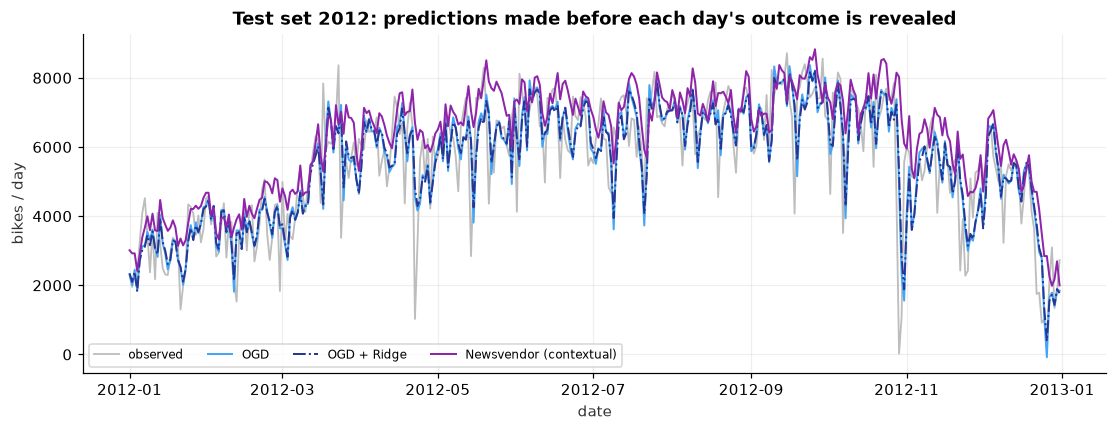

In [18]:
class LagBaseline:
    """Predicts the value observed k days earlier (no learning)."""

    def __init__(self, k):
        self.j = feature_names.index(f"y_lag{k}")

    def params(self):
        return np.zeros(0)

    def predict(self, x):
        return x[self.j]

    def update(self, x, y):
        pass


for name, k in [("Naive (previous day)", 1), ("Naive (previous week)", 7)]:
    pred, params = run_online(LagBaseline(k), X_test, y_test)
    results[name] = {"pred": pred, "params": params, "hyper": "—"}

ORDER = ["Naive (previous day)", "Naive (previous week)", "OGD", "OGD + Ridge", "Newsvendor (no covariates)", "Newsvendor (contextual)"]
results = {name: results[name] for name in ORDER}

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(dates_test, y_test * TARGET_SCALE, color="#BDBDBD", lw=1.2, label="observed")
for name in ["OGD", "OGD + Ridge", "Newsvendor (contextual)"]:
    ax.plot(dates_test, results[name]["pred"] * TARGET_SCALE, color=COLORS[name], ls=STYLES[name], lw=1.3, label=name)
ax.set(title="Test set 2012: predictions made before each day's outcome is revealed", xlabel="date", ylabel="bikes / day")
ax.legend(fontsize=8, ncol=4)
plt.show()

# Part 3 — Final metrics

All metrics cover the **366 days of 2012**, with predictions made before each revelation of demand.
The contextual models (OGD, OGD + Ridge, and Newsvendor (contextual)) now use the current day's weather, assumed known;
the two naive baselines and Newsvendor (no covariates) do not use this information.
Errors are converted back to **bicycles per day**. Bias is defined as *predicted − observed*: positive values indicate overestimation.
We also include the newsvendor cost and coverage $\mathbb P(y_t \le \widehat y_t)$, which should be approximately $\tau = 0{,}75$ for a good quantile.

In [19]:
def final_metrics(pred, y):
    err = (pred - y) * TARGET_SCALE
    return {
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "MAE": np.mean(np.abs(err)),
        "Bias (predicted − observed)": np.mean(err),
        "Newsvendor cost / day": newsvendor_loss(pred, y).mean() * TARGET_SCALE,
        "Coverage P(y ≤ ŷ)": np.mean(y <= pred),
    }


scorecard = pd.DataFrame({name: final_metrics(r["pred"], y_test) for name, r in results.items()}).T
scorecard.insert(0, "hyperparameter", [r["hyper"] for r in results.values()])
display(scorecard.style.format({"RMSE": "{:,.0f}", "MAE": "{:,.0f}", "Bias (predicted − observed)": "{:+,.0f}",
                                "Newsvendor cost / day": "{:,.0f}", "Coverage P(y ≤ ŷ)": "{:.2f}"}))

,hyperparameter,RMSE,MAE,Bias (predicted − observed),Newsvendor cost / day,Coverage P(y ≤ ŷ)
Naive (previous day),—,"1,246",870,-1,"1,741",0.46
Naive (previous week),—,"1,562","1,110",+2,"2,218",0.48
OGD,η = 0.1,"1,041",747,-27,"1,520",0.47
OGD + Ridge,λ = 0.001,"1,031",737,-30,"1,503",0.47
Newsvendor (no covariates),η = 0.01,"1,461","1,014",+795,"1,232",0.74
Newsvendor (contextual),η = 0.003,"1,295",909,+669,"1,149",0.74


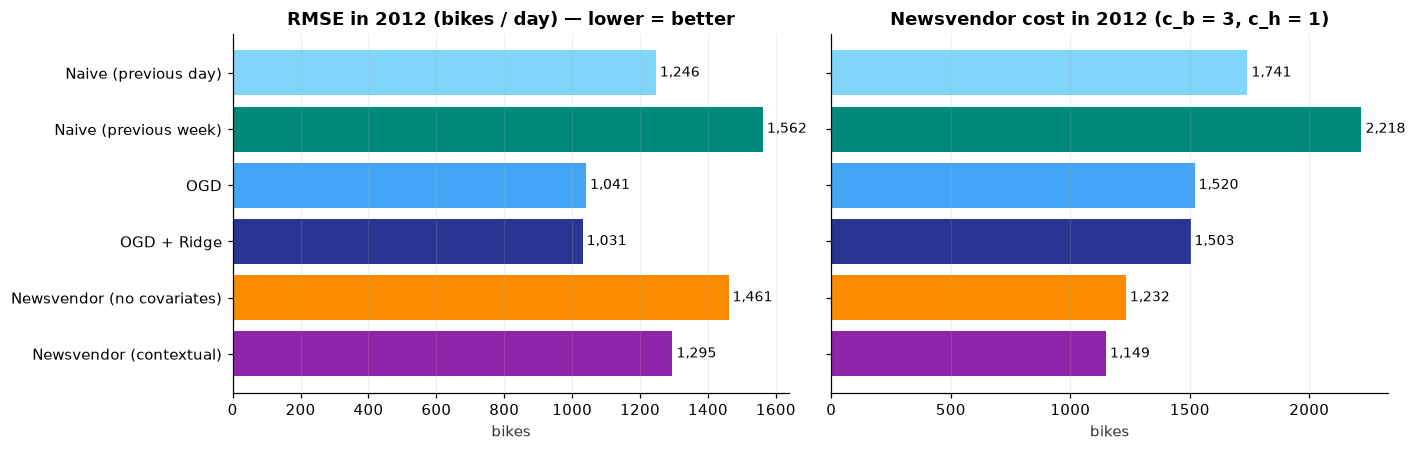

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
panels = [("RMSE", "RMSE in 2012 (bikes / day) — lower = better"),
          ("Newsvendor cost / day", f"Newsvendor cost in 2012 (c_b = {C_B:g}, c_h = {C_H:g})")]
for ax, (col, title) in zip(axes, panels):
    values = scorecard[col].astype(float)
    ax.barh(values.index, values.values, color=[COLORS[n] for n in values.index])
    for i, v in enumerate(values.values):
        ax.text(v, i, f" {v:,.0f}", va="center", fontsize=9)
    ax.invert_yaxis()
    ax.set(title=title, xlabel="bikes")
    ax.grid(axis="y", visible=False)
axes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

<div style="border-left:4px solid #8E24AA;padding:8px 14px;background:#F3E5F5;color:black">
<b>RMSE and newsvendor cost address two different needs.</b><br>
The two families do not address the same need.

- The squared-loss models (OGD, OGD + Ridge) answer <b>“how many bicycles will be rented?”</b>. They target the <b>mean</b>
  of the conditional distribution, and RMSE is the natural score for this question.
- The newsvendor models answer <b>“how many bicycles should I make available?”</b>, given that a stockout costs three times
  as much as a bicycle held idle. They target the <b>0,75 quantile</b> and therefore intentionally order above expected demand:
  positive bias, about 75 % of days without a stockout, a higher RMSE, and a lower newsvendor cost.

Each model should be evaluated using the loss associated with the decision it informs. Ranking newsvendor models by RMSE, or squared-loss models
by newsvendor cost, would amount to comparing answers to two different questions.
</div>

**Interpretation.**

- **Each model performs well on the loss it optimizes.** The left panel rewards prediction of the mean, the right panel the inventory decision.
- **Newsvendor (no covariates)** tracks the demand level with a lag, since $q_t$ is corrected every day. It has no information about the day
  of the week, public holidays, or weather: the contextual model can use this information to adapt its orders.
- **OGD versus the naive baselines:** beating Naive (previous day) is not guaranteed. Naive (previous day) is already a very good predictor for a time series
  this persistent, and it is the benchmark for assessing the actual value of an algorithm.
- **OGD + Ridge versus OGD:** shrinkage and a decreasing step size can reduce accuracy, even if the theoretical guarantee is better.

## Average regret over time

For each prefix of $n$ days from the test set, we compute
$$
\frac{R_n}{n} = \frac1n\Big(\sum_{j=1}^n \ell_j(\theta_j) - \min_{u \in \mathcal K}\sum_{j=1}^n \ell_j(u)\Big),
$$
**each model using its own loss**, namely the one in its theorem. The comparator is **a single** fixed parameter per prefix, recomputed at each $n$.

- **Squared loss (and OGD + Ridge):** $\min_{\|u\|\le B} \tfrac12 u^\top A u - b^\top u$ with $A = \sum \mathbf x_j\mathbf x_j^\top$ (plus $n\lambda I$ for OGD + Ridge)
  and $b = \sum y_j \mathbf x_j$. If the least-squares solution lies in the ball, it is the comparator. Otherwise, the KKT conditions are:
  $(A + \mu I)u = b$ with $\|u\| = B$ and $\mu > 0$, where $\mu$ is found by root-finding.
- **Newsvendor (no covariates):** the comparator is a constant order; the cost is piecewise linear, so the optimum is attained at $0$, at $Q_{\max}$, or at an observed value.
- **Newsvendor (contextual):** quantile regression, solved by linear programming. We check that the solution lies in the ball.
  If it does not, the computed comparator is too good and the curve overestimates regret: this is a conservative upper bound.

In [21]:
def constrained_quadratic_min(A, b, radius=B):
    """argmin_{||u||₂ ≤ radius} ½ uᵀAu − bᵀu, for symmetric positive semidefinite A."""
    w, V = np.linalg.eigh(A)
    w = np.clip(w, 0.0, None)
    c = V.T @ b
    in_range = w > 1e-12 * max(w.max(), 1.0)
    # 1) inactive constraint: minimum-norm solution of Au = b, if it exists and is feasible
    if np.allclose(c[~in_range], 0.0, atol=1e-12):
        u = V[:, in_range] @ (c[in_range] / w[in_range])
        if np.linalg.norm(u) <= radius:
            return u
    # 2) active constraint: (A + μI)u = b and ||u|| = radius, with μ > 0 found by root finding
    norm_u = lambda mu: np.linalg.norm(c / (w + mu))
    mu = brentq(lambda m: norm_u(m) - radius, 1e-15, np.linalg.norm(c) / radius) if norm_u(1e-15) > radius else 1e-15
    return V @ (c / (w + mu))


def avg_regret_quadratic(X, y, pred, params=None, lam=0.0):
    """R_n / n for squared loss (lam = 0) or ridge loss (lam > 0), at each prefix n."""
    d = X.shape[1]
    A, b, yy, loss_alg = np.zeros((d, d)), np.zeros(d), 0.0, 0.0
    out = np.empty(len(y))
    for n in range(len(y)):
        x = X[n]
        A += np.outer(x, x); b += y[n] * x; yy += y[n] ** 2
        loss_alg += squared_loss(pred[n], y[n]) + (0.5 * lam * params[n] @ params[n] if lam > 0 else 0.0)
        A_n = A + (n + 1) * lam * np.eye(d)
        u = constrained_quadratic_min(A_n, b)
        loss_star = 0.5 * u @ A_n @ u - b @ u + 0.5 * yy
        out[n] = (loss_alg - loss_star) / (n + 1)
    return out


def avg_regret_newsvendor_constant(y, q):
    """R_n / n against the best constant order in [0, Q_max]."""
    loss_alg = np.cumsum(newsvendor_loss(q, y))
    out = np.empty(len(y))
    for n in range(1, len(y) + 1):
        candidates = np.clip(np.concatenate([[0.0, Q_MAX], y[:n]]), 0.0, Q_MAX)
        loss_star = newsvendor_loss(candidates[:, None], y[None, :n]).sum(axis=1).min()
        out[n - 1] = (loss_alg[n - 1] - loss_star) / n
    return out


def avg_regret_newsvendor_contextual(X, y, q):
    """R_n / n against the best fixed linear quantile regression (linear program)."""
    loss_alg = np.cumsum(newsvendor_loss(q, y))
    out, inside = np.empty(len(y)), np.empty(len(y), dtype=bool)
    d = X.shape[1]
    for n in range(1, len(y) + 1):
        cost = np.concatenate([np.zeros(d), C_B * np.ones(n), C_H * np.ones(n)])  # θ, (y−q)+, (q−y)+
        A_eq = np.hstack([X[:n], np.eye(n), -np.eye(n)])                          # xᵀθ + u⁺ − u⁻ = y
        res = linprog(cost, A_eq=A_eq, b_eq=y[:n], bounds=[(None, None)] * d + [(0, None)] * (2 * n), method="highs")
        out[n - 1] = (loss_alg[n - 1] - res.fun) / n
        inside[n - 1] = np.linalg.norm(res.x[:d]) <= B
    return out, inside


avg_regret = {
    "Naive (previous day)": avg_regret_quadratic(X_test, y_test, results["Naive (previous day)"]["pred"]),
    "OGD": avg_regret_quadratic(X_test, y_test, results["OGD"]["pred"]),
    "OGD + Ridge": avg_regret_quadratic(X_test, y_test, results["OGD + Ridge"]["pred"],
                                        results["OGD + Ridge"]["params"], lam=results["OGD + Ridge"]["lam"]),
    "Newsvendor (no covariates)": avg_regret_newsvendor_constant(y_test, results["Newsvendor (no covariates)"]["pred"]),
}
avg_regret["Newsvendor (contextual)"], inside = avg_regret_newsvendor_contextual(
    X_test, y_test, results["Newsvendor (contextual)"]["pred"])
print(f"Contextual comparator in K for {inside.mean():.0%} of prefixes "
      f"({inside[30:].mean():.0%} after 30 days).")

Contextual comparator in K for 95% of prefixes (100% after 30 days).


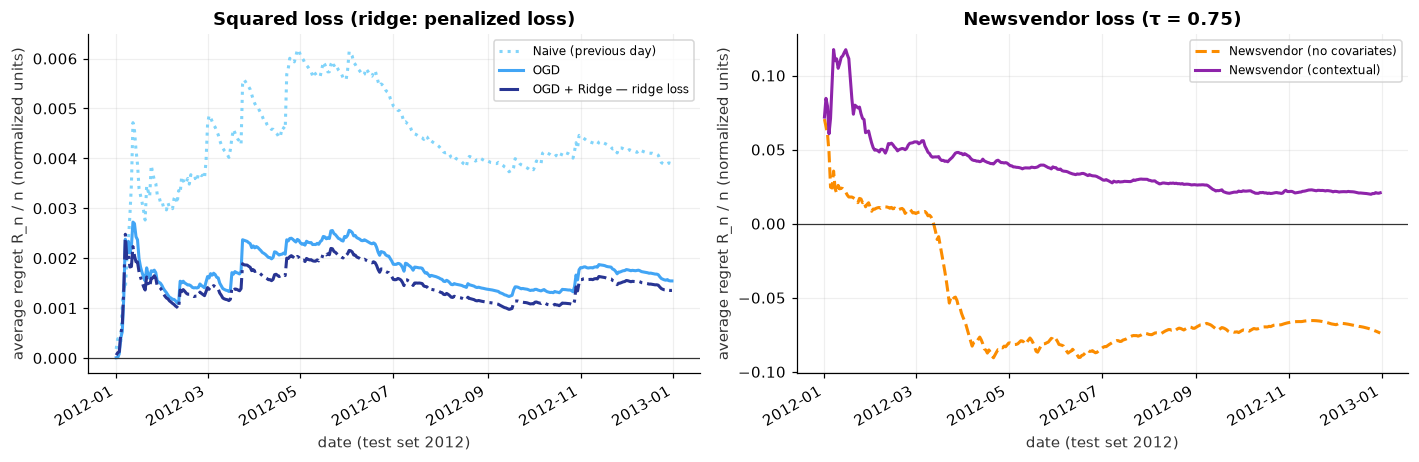

,R_n / n at the end of the test set
Naive (previous day),+0.00390
OGD,+0.00154
OGD + Ridge,+0.00135
Newsvendor (no covariates),-0.07385
Newsvendor (contextual),+0.02085


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharex=True)
panels = [
    (axes[0], ["Naive (previous day)", "OGD", "OGD + Ridge"], "Squared loss (ridge: penalized loss)"),
    (axes[1], ["Newsvendor (no covariates)", "Newsvendor (contextual)"], f"Newsvendor loss (τ = {TAU})"),
]
for ax, names, title in panels:
    for name in names:
        label = name + (" — ridge loss" if name == "OGD + Ridge" else "")
        ax.plot(dates_test, avg_regret[name], color=COLORS[name], ls=STYLES[name], label=label)
    ax.axhline(0, color="#333333", lw=0.8)
    ax.set(title=title, xlabel="date (test set 2012)", ylabel="average regret R_n / n (normalized units)")
    ax.legend(fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

display(pd.Series({name: r[-1] for name, r in avg_regret.items()},
                  name="R_n / n at the end of the test set").to_frame().style.format("{:+.5f}"))

**Interpretation.**

- **Regret can be negative, and substantially so.** Newsvendor (no covariates) is a typical example: its order tracks the growth
  in 2012, whereas the comparator is **a single** order for the entire year, too high in winter and too low in summer.
  Beating this comparator therefore does not say much. The guarantee controls only $\max(R_n, 0)/n$.
- **The comparator depends on the model class.** Newsvendor (contextual) competes against a fixed linear quantile regression, much stronger
  than a constant: its regret is positive even though its cost is of the same order.
- **The first few days are noisy:** for small $n$, the comparator fits the few points seen almost perfectly, hence the high average regret.
  The curve then stabilizes.
- **Naive (previous day)** has average regret that does not converge to 0: it is a fixed parameter in $\mathcal K$ that is not the best. Low average regret
  does not, however, imply a low error: it measures the gap to **one** comparator, not absolute quality.
- **OGD + Ridge:** its regret is measured using the penalized loss; it is not directly comparable to the other two curves in the panel.
- **A finite curve proves no asymptotic result.** It illustrates the guarantee without proving it, and the theoretical bounds computed in Question 2.1 are far higher.

## Conclusion

The cell below summarizes **your** numerical results. The following messages do not depend on the exact figures.

In [23]:
print("Scenario: temp, weathersit and windspeed for day t known before the decision.")
best_rmse = scorecard["RMSE"].astype(float).idxmin()
best_cost = scorecard["Newsvendor cost / day"].astype(float).idxmin()
ogd_vs_naive = scorecard.loc["OGD", "RMSE"] / scorecard.loc["Naive (previous day)", "RMSE"] - 1
print(f"• Best RMSE in 2012: {best_rmse} ({scorecard.loc[best_rmse, 'RMSE']:,.0f} bikes / day).")
print(f"• OGD versus the previous day: RMSE {ogd_vs_naive:+.1%}.")
print(f"• Best newsvendor cost: {best_cost} ({scorecard.loc[best_cost, 'Newsvendor cost / day']:,.0f} / day).")
print(f"• Coverage P(y ≤ q): no covariates = {scorecard.loc['Newsvendor (no covariates)', 'Coverage P(y ≤ ŷ)']:.2f}, "
      f"contextual = {scorecard.loc['Newsvendor (contextual)', 'Coverage P(y ≤ ŷ)']:.2f} (target {TAU}).")
print("• Final average regret: " + ", ".join(f"{k} {v[-1]:+.4f}" for k, v in avg_regret.items()) + ".")

Scenario: temp, weathersit and windspeed for day t known before the decision.
• Best RMSE in 2012: OGD + Ridge (1,031 bikes / day).
• OGD versus the previous day: RMSE -16.5%.
• Best newsvendor cost: Newsvendor (contextual) (1,149 / day).
• Coverage P(y ≤ q): no covariates = 0.74, contextual = 0.74 (target 0.75).
• Final average regret: Naive (previous day) +0.0039, OGD +0.0015, OGD + Ridge +0.0014, Newsvendor (no covariates) -0.0739, Newsvendor (contextual) +0.0209.


**Key takeaways.**

1. **The loss defines the decision.** Squared loss targets the conditional mean, newsvendor loss the quantile $\tau = c_b/(c_b+c_h)$.
   We have verified this: the best constant order is the empirical quantile, and an online newsvendor policy covers approximately $\tau$ of the days.
   A newsvendor model with a higher RMSE is not a worse model: it answers a different question.
2. **One algorithm for everything:** a (sub)gradient, then a projection. Only the loss and the step size change.
3. **The assumptions are constructed.** Compactness of $\mathcal K$, bounded covariates and target: these are obtained through modeling choices
   stated **a priori** (scaling, bounded covariates, radius $B$), never estimated on the test set.
4. **The protocol matters as much as the algorithm:** predict before learning, split by date, choose the hyperparameters on the training set
   and compare against naive baselines. The current day's weather is admissible here only because it is assumed known before the decision;
   the results are conditional on this assumption and do not measure the quality of genuine weather forecasts.
5. **Regret has its limits.** It compares against a **fixed** parameter: with growing demand, being no-regret guarantees neither low error
   nor good tracking. This would require **dynamic** regret, against a slowly varying sequence of comparators.

**Further exploration.** Compare observed weather assumed known, a genuine weather forecast, and a version without weather; replace the constant step size with $\eta_t = \eta_0/\sqrt t$; measure regret against
one comparator per quarter; ask what `cnt` really measures as “demand”, since on days with station stockouts, unmet demand is not observed.